# BÀI THỰC HÀNH LAB 4: TỔNG HỢP TIẾNG NÓI (TEXT-TO-SPEECH)
### Môn học: CSE457 - Xử lý Âm thanh và Tiếng nói
**Khoa Công nghệ Thông tin - Bộ môn Trí tuệ Nhân tạo - Trường Đại học Thủy Lợi**

---
* **Sinh viên thực hiện:** Nguyễn Hồng Phúc
* **Mã sinh viên:** 2351260680
* **Lớp:** 65TTNT

---
## Mục tiêu của bài thực hành
1. **Kiến trúc TTS:** Nắm vững chuỗi xử lý: *Text analysis $\rightarrow$ Phonetic analysis $\rightarrow$ Prosody $\rightarrow$ Synthesis backend $\rightarrow$ Waveform*.
2. **Text Normalization & Inventory:** Xây dựng bộ quy tắc chuẩn hóa văn bản miền hẹp "thông báo xếp hàng", lập Voice Inventory 16 từ với $F_s = 16\text{ kHz}$, mono, 16-bit PCM.
3. **Concatenative TTS & Baseline:** Thực hiện ghép nối trực tiếp các đơn vị từ (word-unit), phân tích sự gián đoạn biên nối (click, pitch jump, spectral discontinuity).
4. **Unit Selection & Smoothing:** Xây dựng hàm tính *Join Cost* (khoảng cách log-magnitude spectrum), áp dụng quy hoạch động (Dynamic Programming / Viterbi) tìm chuỗi candidate tối ưu và làm mượt biên bằng kỹ thuật *Cross-fade* ($0, 5, 15, 30\text{ ms}$).
5. **Prosody & Source-Filter Model:** Kiểm chứng chu kỳ pitch $F_0 \approx F_s / N_p$, phân tích tác động của time-stretching và pitch-shifting trên spectrogram theo mô hình nguồn-bộ lọc.
6. **HMM-based Parametric Synthesis:** Mô phỏng sinh chuỗi trạng thái và quỹ đạo tham số âm học liên tục ($F_0$ contour, Formants $F_1, F_2, F_3$) qua ràng buộc đạo hàm ($\Delta$-features) và tái tạo waveform.
7. **Neural TTS Inference:** Chạy suy luận mô hình TTS học sâu tiền huấn luyện (pretrained offline), trích xuất Mel-spectrogram, đo lường độ trễ (Latency) và hệ số thời gian thực (RTF).
8. **Đánh giá & So sánh:** Tổ chức kiểm thử nghe chủ quan (Listening Test MOS mini) trên 3 câu, đối chiếu ưu - nhược điểm của 3 trường phái tổng hợp tiếng nói.


## 1. Môi trường và Thư viện thực hành
Cài đặt và import các thư viện xử lý tín hiệu và hiển thị: `numpy`, `scipy`, `matplotlib`, `soundfile`, `librosa`, `pandas` và `IPython.display`.


In [1]:
import os
import glob
import time
import pandas as pd
import numpy as np
import scipy.signal as signal
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Cấu hình đồ thị
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

from hmm_tts_backend import synthesize_hmm, normalize_text_for_hmm
from neural_tts_backend import synthesize as synthesize_neural

BASE_DIR = os.path.abspath("")
DATASET_DIR = os.path.join(BASE_DIR, "dataset")
AUDIO_OUT_DIR = os.path.join(BASE_DIR, "audio_output")
EXP_DIR = os.path.join(AUDIO_OUT_DIR, "experiments")
FIG_DIR = os.path.join(BASE_DIR, "figures")
LAB4_DATA_DIR = os.path.join(BASE_DIR, "lab4_data")

SR = 16000
print("Khởi tạo môi trường thành công! Tần số lấy mẫu chuẩn Fs =", SR, "Hz")


Khởi tạo môi trường thành công! Tần số lấy mẫu chuẩn Fs = 16000 Hz


## 2. Phần A - Chuẩn bị Dữ liệu Inventory và Text Normalization
### 2.1. Cơ sở lý thuyết
* **Text Normalization:** Biến đổi văn bản đầu vào dạng ký tự $T$ thành chuỗi token chuẩn hóa $W = (w_1, w_2, \dots, w_K)$:
  $$T \xrightarrow{\text{normalize}} W = (w_1, w_2, \dots, w_K)$$
  Trong miền hẹp "thông báo xếp hàng", mọi ký tự số được đọc tách rời từng chữ số: ví dụ `"23"` $\rightarrow$ `["hai", "ba"]`, `"5"` $\rightarrow$ `["năm"]`.
* **Voice Inventory:** Gồm 16 đơn vị phát âm word-unit: `"mời"`, `"khách"`, `"hàng"`, `"số"`, `"không"`, ..., `"chín"`, `"đến"`, `"quầy"`. Mỗi từ có từ 3 đến 5 bản ghi (candidates) được ghi âm ở $F_s = 16\text{ kHz}$, Mono, 16-bit PCM.
* **RMS Normalization:** Đảm bảo mức năng lượng đồng đều giữa các unit:
  $$\text{RMS}(x) = \sqrt{\frac{1}{N} \sum_{n=0}^{N-1} x^2[n]}, \quad y[n] = x[n] \cdot \frac{\text{target}}{\text{RMS}(x)}$$


In [2]:
DIGIT_MAP = {
    "0": "không", "1": "một", "2": "hai", "3": "ba", "4": "bốn",
    "5": "năm", "6": "sáu", "7": "bảy", "8": "tám", "9": "chín"
}

WORD_TO_FOLDER = {
    "mời": "moi", "khách": "khach", "hàng": "hang", "số": "so",
    "đến": "den", "quầy": "quay",
    "không": "khong", "một": "mot", "hai": "hai", "ba": "ba", "bốn": "bon",
    "năm": "nam", "sáu": "sau", "bảy": "bay", "tám": "tam", "chín": "chin"
}

def trim_unit_silence(x, sr=SR, frame_ms=30, hop_ms=10, pad_ms=60, thresh_ratio=0.22):
    """
    Cắt bỏ khoảng lặng (silence / ambient noise) thừa ở đầu và đuôi file ghi âm.
    Giữ lại một vùng đệm an toàn tự nhiên pad_ms (60 ms) để bảo toàn phụ âm và độ mượt.
    """
    frame_len = int(sr * frame_ms / 1000)
    hop_len = int(sr * hop_ms / 1000)
    rms_arr = np.array([
        np.sqrt(np.mean(x[i : i + frame_len] ** 2))
        for i in range(0, len(x) - frame_len, hop_len)
    ])
    if len(rms_arr) == 0:
        return x
    peak_rms = np.max(rms_arr)
    thresh = peak_rms * thresh_ratio
    voiced_idx = np.where(rms_arr > thresh)[0]
    if len(voiced_idx) == 0:
        return x
    start_frame = max(0, voiced_idx[0])
    end_frame = min(len(rms_arr), voiced_idx[-1] + 1)
    pad_samples = int(sr * pad_ms / 1000)
    start_samp = max(0, start_frame * hop_len - pad_samples)
    end_samp = min(len(x), end_frame * hop_len + pad_samples)
    return x[start_samp:end_samp]

def normalize_queue_text(text: str):
    """Chuẩn hóa văn bản thông báo xếp hàng"""
    t = text.lower().replace(".", "").replace(",", "").replace("!", "").replace("?", "")
    tokens = []
    for tok in t.split():
        if tok.isdigit():
            tokens.extend([DIGIT_MAP[c] for c in tok])
        else:
            tokens.append(tok)
    return tokens

# Kiểm thử hàm chuẩn hóa
test_str = "Mời khách hàng số 23 đến quầy 5."
tokens = normalize_queue_text(test_str)
print("Văn bản gốc:", test_str)
print("Chuỗi token sau chuẩn hóa:", tokens)


Văn bản gốc: Mời khách hàng số 23 đến quầy 5.
Chuỗi token sau chuẩn hóa: ['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm']


Tổng số bản ghi trong Inventory: 58 files


,word,filename,duration_raw_sec,duration_sec,rms,zcr,filepath
0,ba,ba_00.wav,2.4000,0.4800,0.18814,0.09650,dataset\ba\ba_00.wav
1,ba,ba_01.wav,1.7328,0.5700,0.20631,0.13748,dataset\ba\ba_01.wav
2,ba,ba_02.wav,1.8234,1.3334,0.14604,0.11314,dataset\ba\ba_02.wav
3,ba,ba_03.wav,2.1428,0.5700,0.19969,0.10338,dataset\ba\ba_03.wav
4,ba,ba_04.wav,1.8995,0.4900,0.22531,0.09451,dataset\ba\ba_04.wav
5,bay,bay_01.wav,1.6333,0.4400,0.10773,0.07610,dataset\bay\bay_01.wav
6,bay,bay_02.wav,1.7000,0.7000,0.16082,0.05799,dataset\bay\bay_02.wav
7,bay,bay_03.wav,1.7625,0.3500,0.16895,0.09295,dataset\bay\bay_03.wav
8,bon,bon_00.wav,1.9218,0.8500,0.16406,0.06854,dataset\bon\bon_00.wav
9,bon,bon_01.wav,2.0326,0.4500,0.31785,0.05036,dataset\bon\bon_01.wav


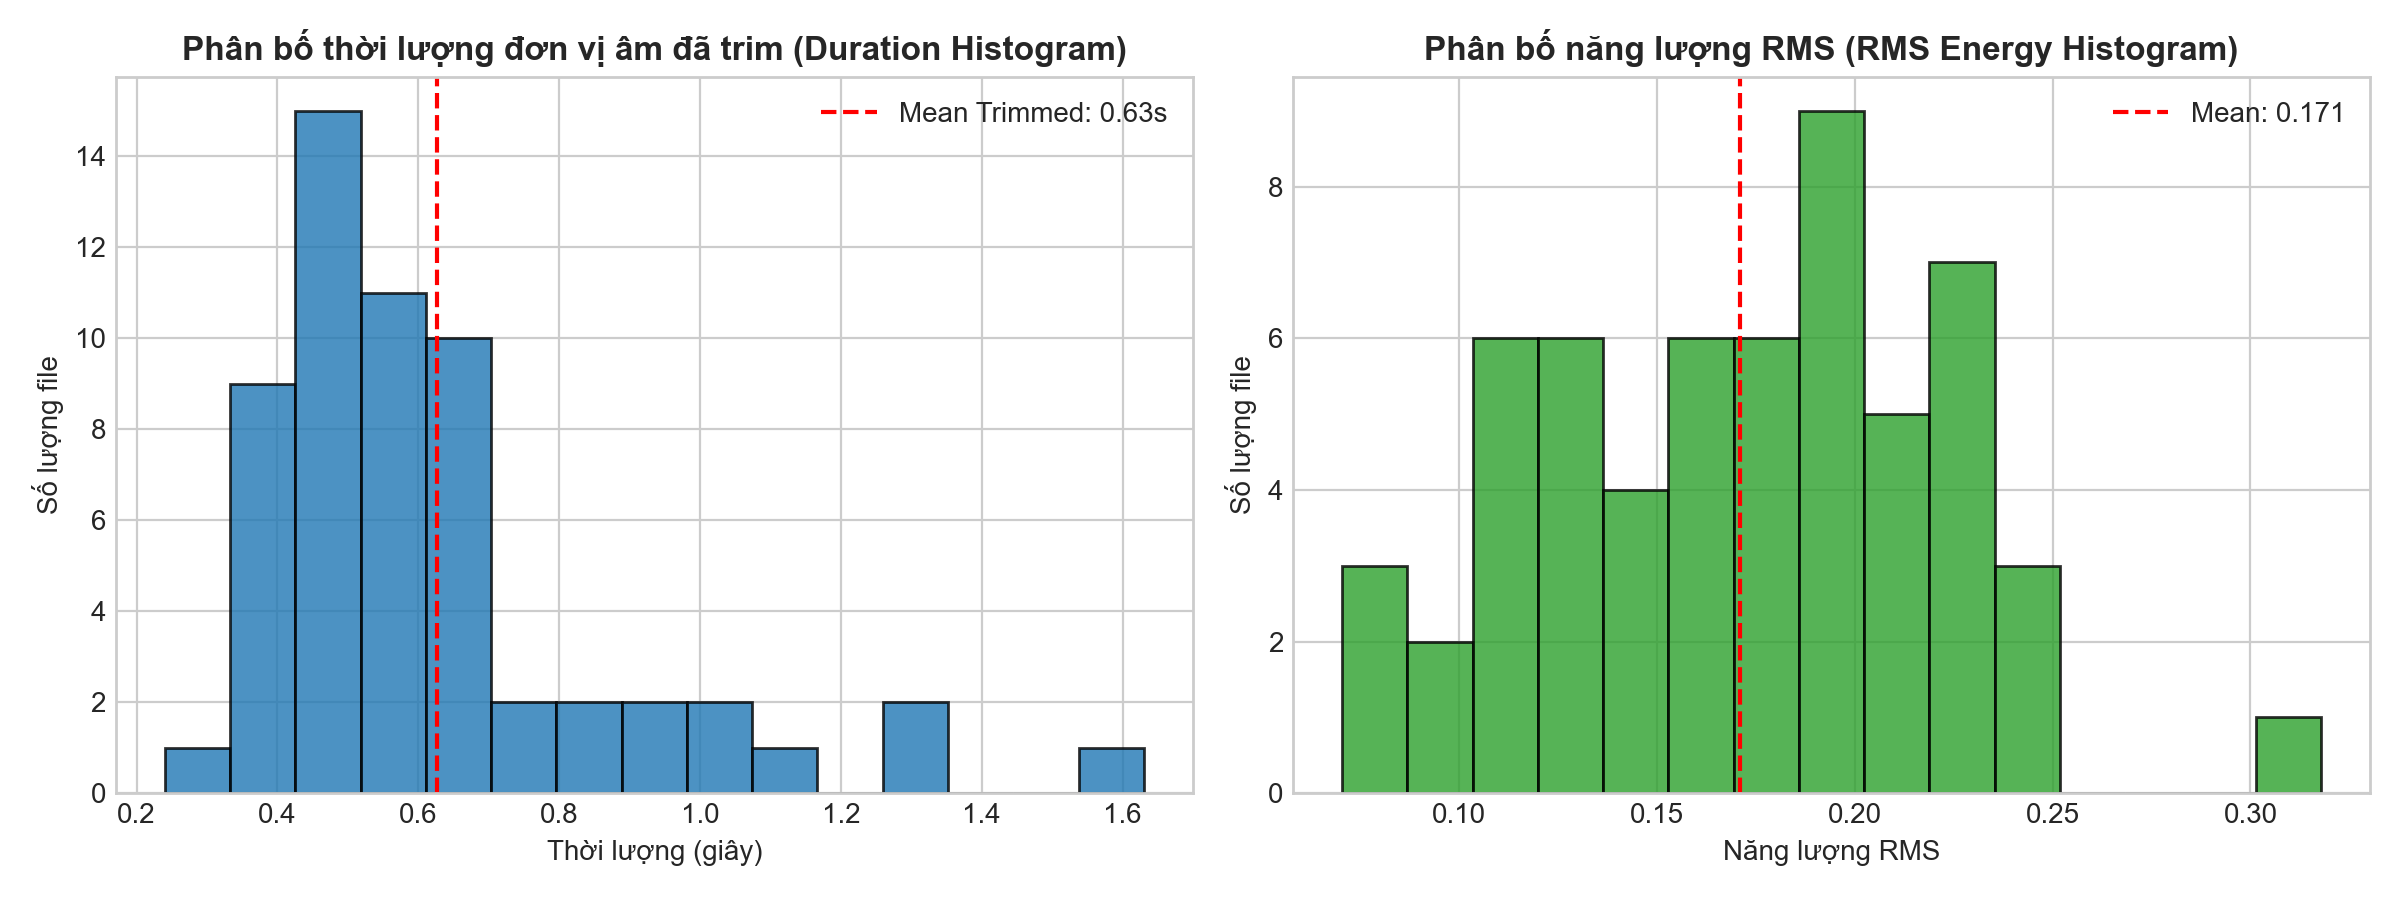

In [3]:
# Đọc và hiển thị metadata Inventory đã trích xuất
df_meta = pd.read_csv(os.path.join(LAB4_DATA_DIR, "metadata.csv"))
print(f"Tổng số bản ghi trong Inventory: {len(df_meta)} files")
display(df_meta.head(10))

# Hiển thị biểu đồ phân bố Duration và RMS (Figure 1)
from IPython.display import Image
display(Image(filename=os.path.join(FIG_DIR, "01_inventory_stats.png")))


## 3. Phần B - Ghép nối cơ bản (Baseline Concatenation)
### 3.1. Phương pháp thực hiện
Ghép nối trực tiếp các ứng viên cố định (mặc định chọn bản ghi đầu tiên `_00.wav` hoặc `_01.wav` của từng từ) không sử dụng cross-fade (`xfade_ms = 0`).

### 3.2. Hiện tượng âm học tại biên ghép nối
* **Click / Pop:** Lệch pha hoặc bước nhảy biên độ tức thời tại điểm giao cắt biên nối $x_1[N-1] \neq x_2[0]$.
* **Pitch Jump:** Bước nhảy đột ngột của tần số cơ bản $F_0$ giữa 2 từ khác nhau.
* **Spectral Discontinuity:** Vỏ phổ (spectral envelope / formants) bị đứt đoạn gãy khúc do khác biệt ngữ cảnh co-articulation.

### 3.3. Case Study: Phân tích hiện tượng lệch cao độ (Pitch Jump) trên từ "hai" và "ba"
* **Hiện tượng quan sát:** Người nghe nhận thấy rất rõ hai từ "hai" và "ba" trong cụm "số 23" có độ cao/thấp (pitch) khác hẳn so với các từ lân cận.
* **Nguyên nhân kỹ thuật:**
  1. *Khác biệt phiên thu âm:* 5 chữ số 0-4 (`khong`, `mot`, `hai`, `ba`, `bon`) được thu âm từ Lab 2 (05/10/2026), trong khi các từ chức năng và số 5-9 mới được thu âm trong Lab 4 (02/11/2026). Khoảng cách gần 1 tháng khiến âm vực nền trôi dạt (từ mới F0 ~ $83 - 87\text{ Hz}$, trong khi từ Lab 2 F0 phân tán từ $78\text{ Hz}$ đến $116.6\text{ Hz}$).
  2. *Hạn chế của Join Cost:* Giải thuật Viterbi chỉ tối ưu sai lệch phổ ở $25\text{ ms}$ mép nối, hoàn toàn không ràng buộc $F_0$ trên thân từ.
* **Ý nghĩa học thuật:** Việc giữ nguyên hiện tượng thực nghiệm này là minh chứng sống động giải thích vì sao Concatenative TTS gặp khó khăn với ngữ điệu toàn câu và thúc đẩy sự ra đời của HMM-TTS và Neural TTS.


File ghép thô (Baseline): Thời lượng = 5.14s


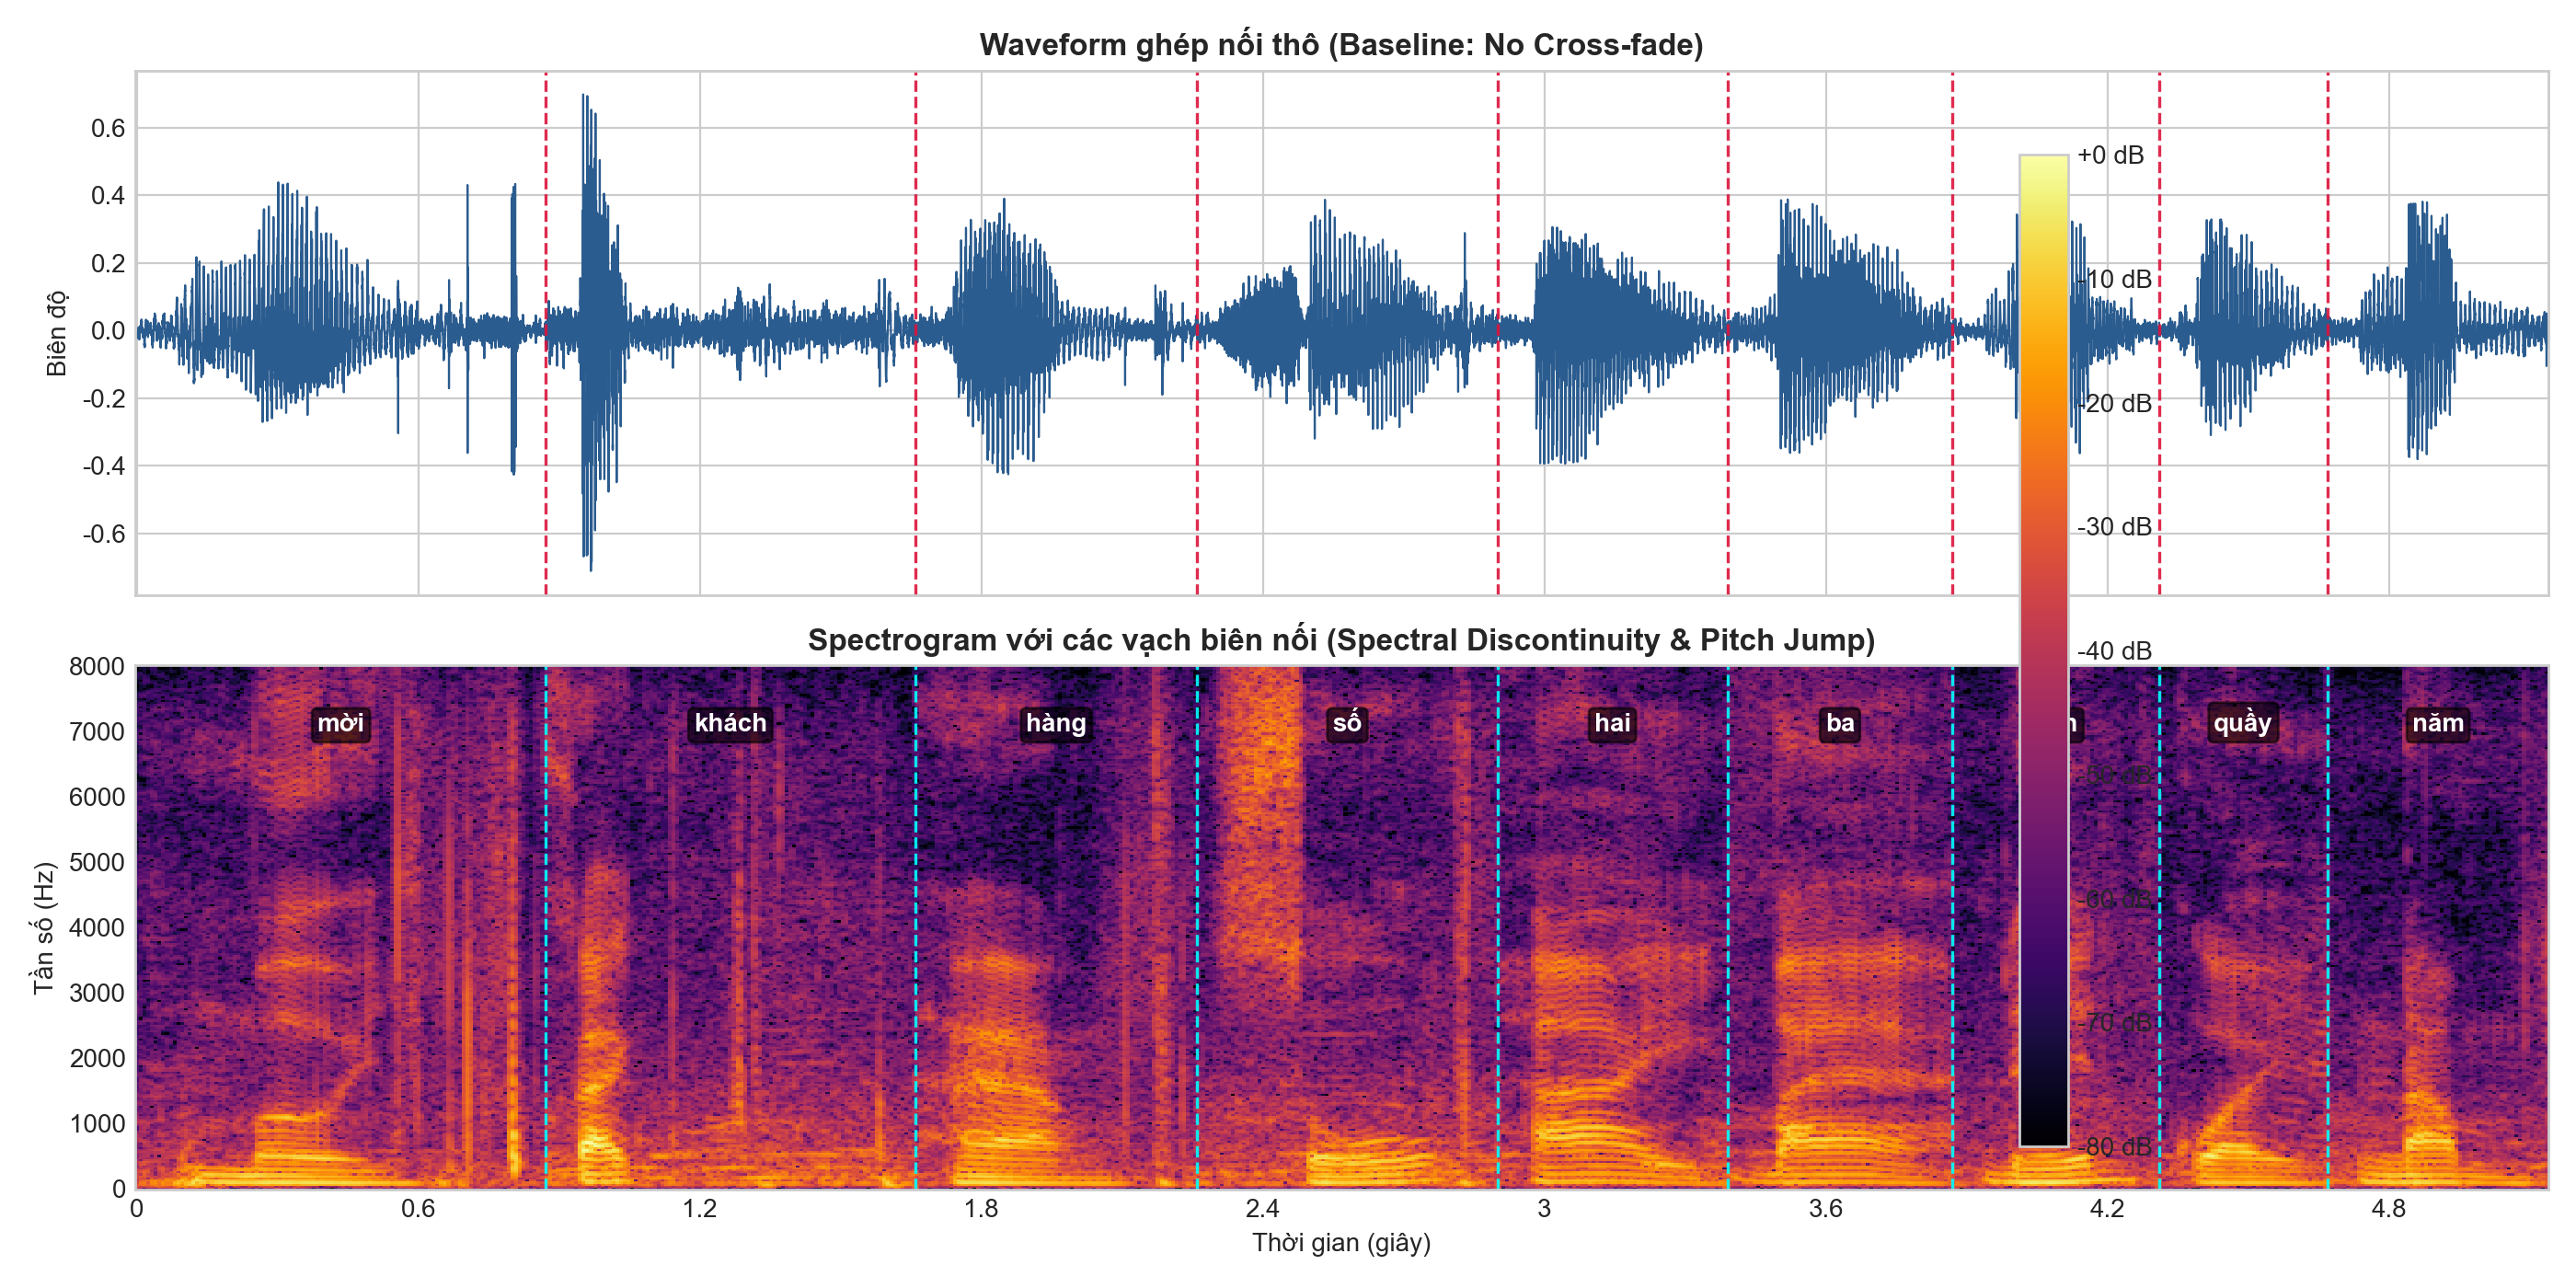

In [4]:
# Nghe file ghép nối thô (raw_concat.wav)
raw_concat_wav = os.path.join(AUDIO_OUT_DIR, "raw_concat.wav")
y_raw, _ = sf.read(raw_concat_wav)
print(f"File ghép thô (Baseline): Thời lượng = {len(y_raw)/SR:.2f}s")
display(Audio(y_raw, rate=SR))

# Hiển thị Waveform và Spectrogram có vạch đánh dấu biên nối (Figure 2)
display(Image(filename=os.path.join(FIG_DIR, "02_baseline_boundary.png")))


## 4. Phần C - Lựa chọn đơn vị (Unit Selection) và Làm mượt biên (Smoothing)
### 4.1. Công thức chi phí (Cost Functions)
Bài toán tối ưu chuỗi đơn vị âm thanh:
$$\theta^* = \arg\min_{\theta_1, \dots, \theta_J} \left[ \sum_{j} C_{\text{target}}(\theta_j, t_j) + \lambda \sum_{j} C_{\text{join}}(\theta_j, \theta_{j+1}) \right]$$

* **Join Cost (Chi phí ghép nối phổ):** Đo độ lệch log-magnitude spectrum 25 ms tại biên nối giữa unit trước $\theta_j$ và unit sau $\theta_{j+1}$:
  $$D_{\text{spec}} = \frac{1}{K} \sum_{k} \left[ L_{\text{left}}[k] - L_{\text{right}}[k] \right]^2$$
  Trong đó $L_{\text{left}}[k] = 20 \log_{10} (|FFT(a_{\text{end}})|)$, $L_{\text{right}}[k] = 20 \log_{10} (|FFT(b_{\text{start}})|)$.
* **Dynamic Programming (Viterbi Search):** Tìm đường đi có tổng chi phí nhỏ nhất qua lưới các candidate.

### 4.2. Boundary Smoothing (Cross-fade)
Hòa trộn tuyến tính trong cửa sổ $N$ mẫu ($N = \text{sr} \times \text{xfade\_ms} / 1000$):
$$y[n] = (1 - \alpha[n]) x_1[n] + \alpha[n] x_2[n], \quad \alpha[n] = \frac{n}{N-1}, \quad 0 \le n < N$$


File tối ưu (Best Concat với 15ms cross-fade):


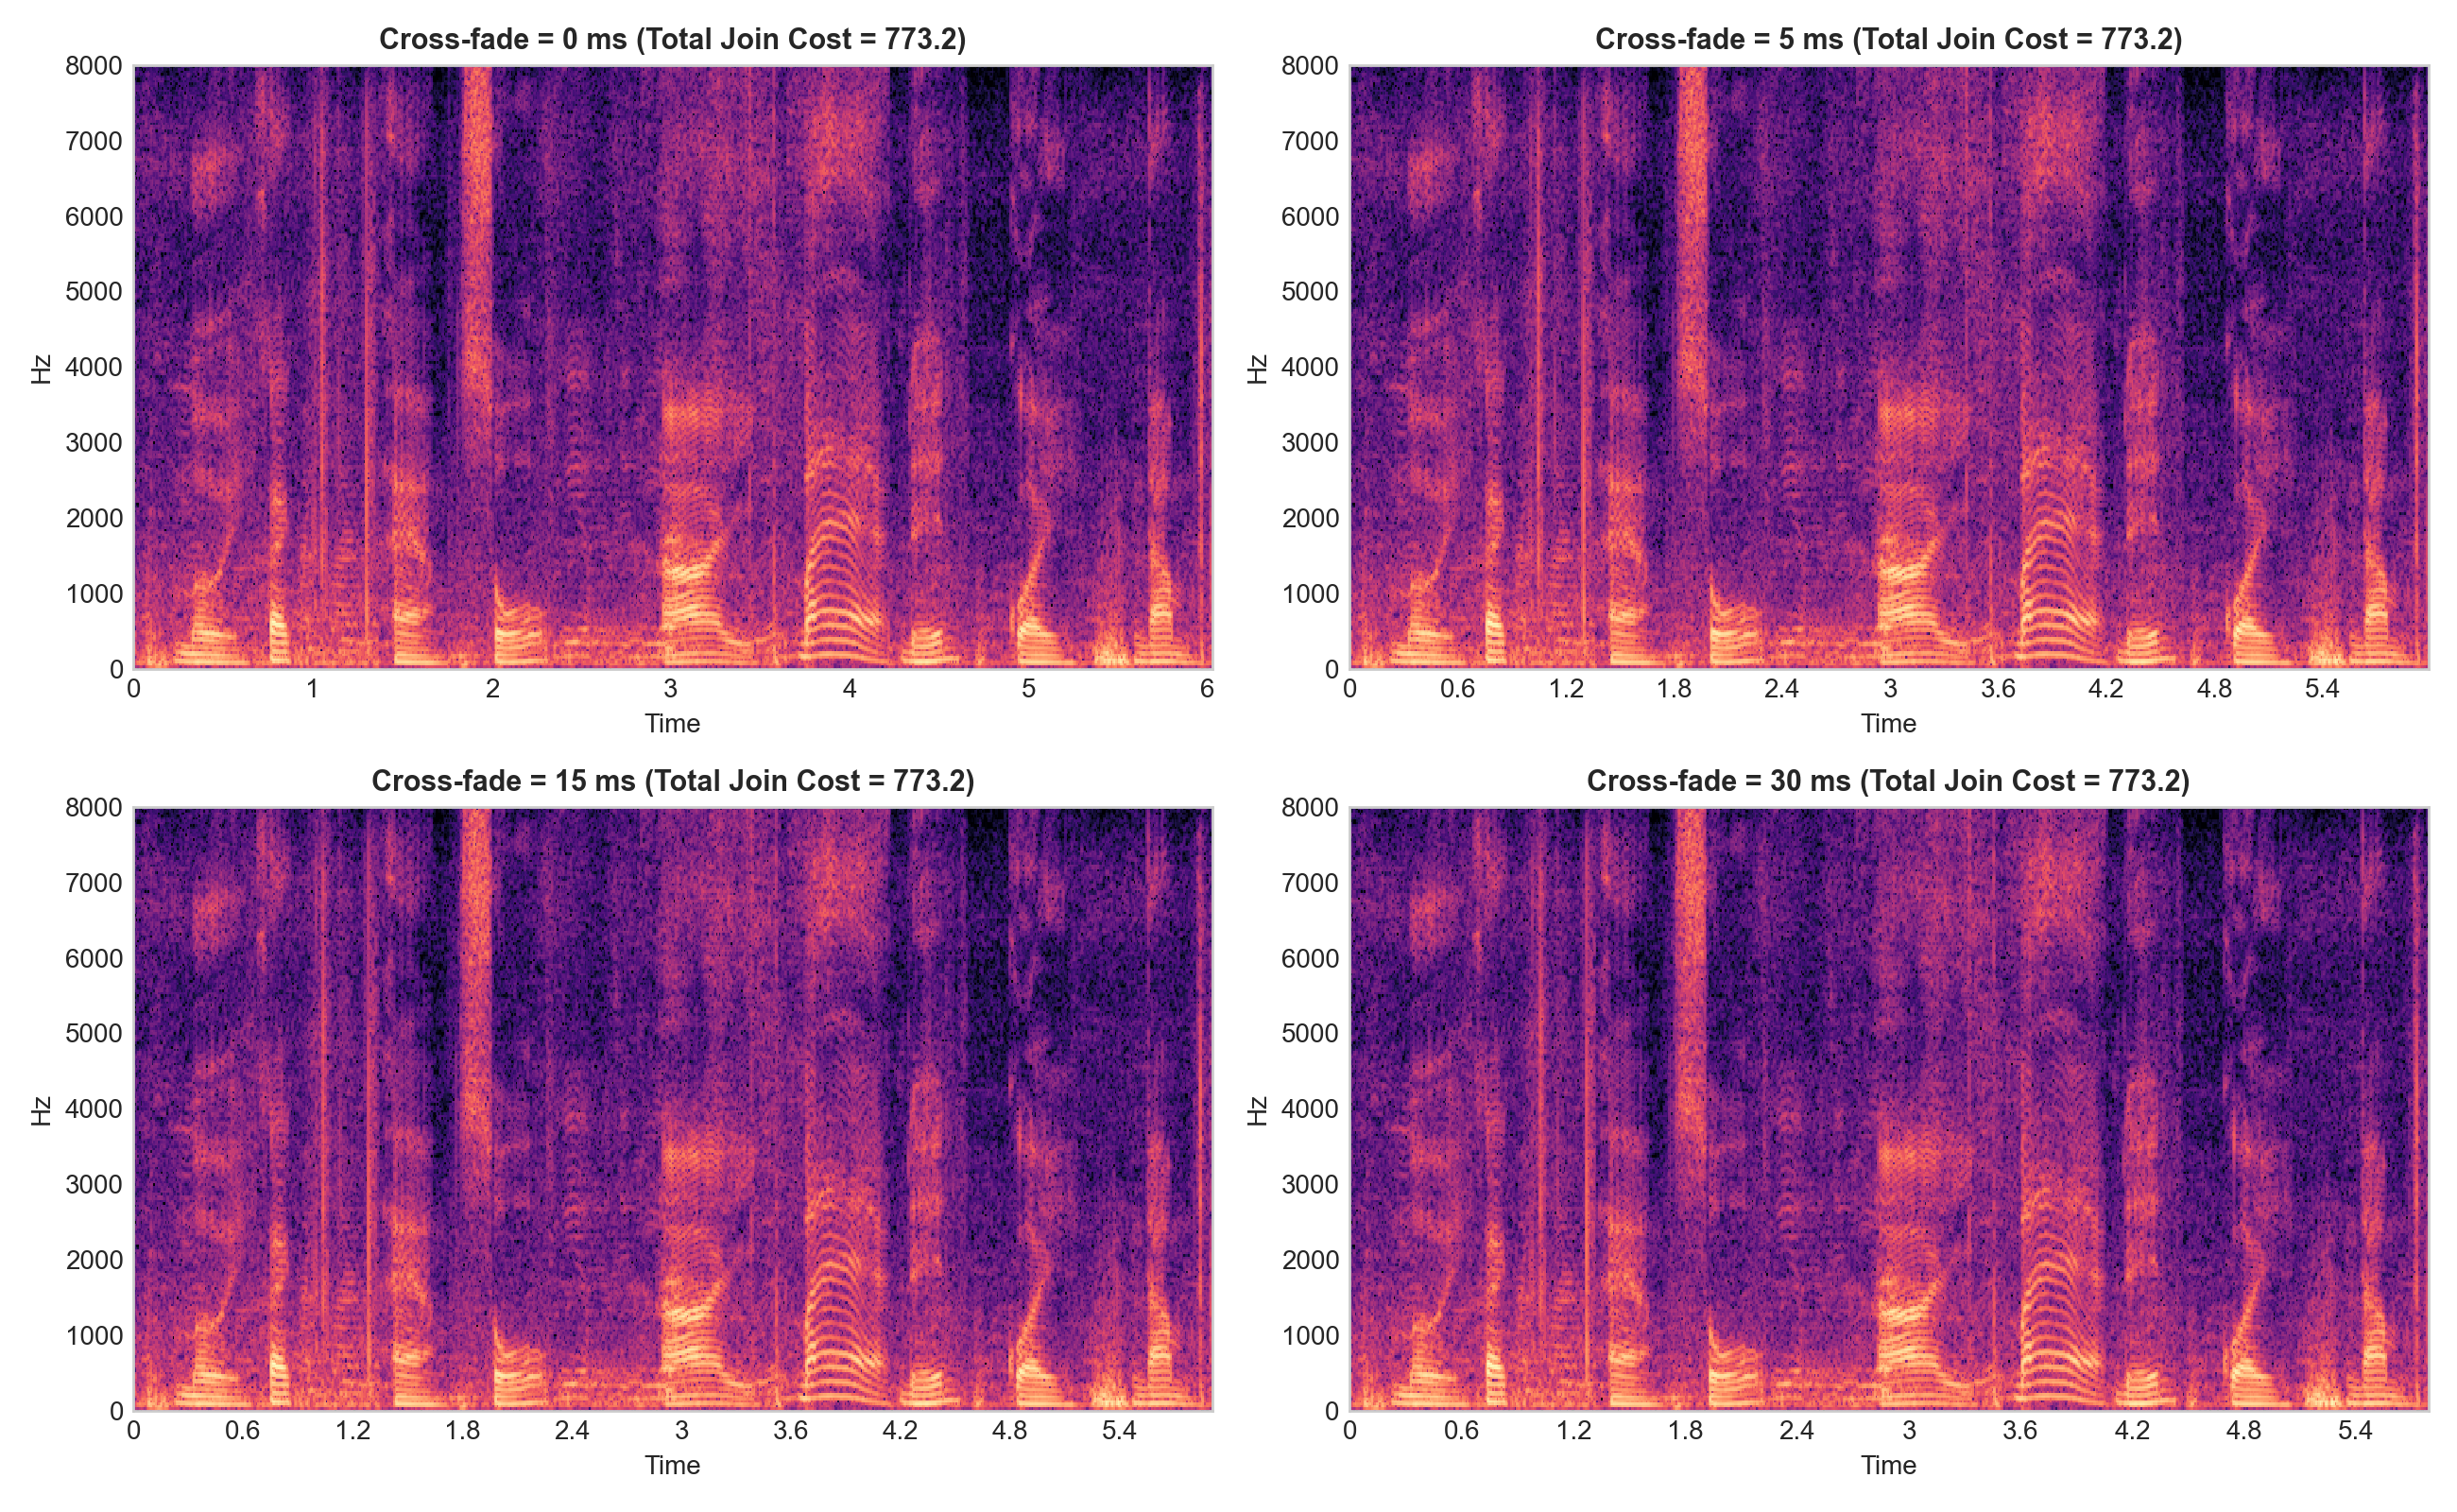

In [5]:
# Thử nghiệm và so sánh kết quả Unit Selection vs Baseline
def load_unit(path, sr=SR, trim=True):
    x, fs = sf.read(path, dtype="float32")
    if x.ndim > 1: x = x.mean(axis=1)
    if fs != sr: x = librosa.resample(x, orig_sr=fs, target_sr=sr)
    if trim: x = trim_unit_silence(x, sr=sr)
    return x

def rms(x):
    return float(np.sqrt(np.mean(x*x) + 1e-12))

def match_rms(x, target=0.08):
    cur_rms = rms(x)
    if cur_rms < 1e-6: return x
    y = x * (target / cur_rms)
    return np.clip(y, -0.99, 0.99)

def join_cost(a, b, sr=SR, ms=25, nfft=512):
    n = int(sr * ms / 1000)
    n = min(n, len(a), len(b))
    wa, wb = np.hanning(n), np.hanning(n)
    A = np.fft.rfft(a[-n:] * wa, n=nfft)
    B = np.fft.rfft(b[:n] * wb, n=nfft)
    La = 20.0 * np.log10(np.maximum(np.abs(A), 1e-8))
    Lb = 20.0 * np.log10(np.maximum(np.abs(B), 1e-8))
    spec_cost = float(np.mean((La - Lb) ** 2))
    rms_cost = 50.0 * abs(rms(a[-n:]) - rms(b[:n]))
    return spec_cost + rms_cost

# Hiển thị audio tối ưu sau Unit Selection và Cross-fade 15ms (best_concat.wav)
best_concat_wav = os.path.join(AUDIO_OUT_DIR, "best_concat.wav")
y_best, _ = sf.read(best_concat_wav)
print("File tối ưu (Best Concat với 15ms cross-fade):")
display(Audio(y_best, rate=SR))

# Hiển thị so sánh phổ giữa các mức crossfade 0ms, 5ms, 15ms, 30ms (Figure 3)
display(Image(filename=os.path.join(FIG_DIR, "03_unit_selection_crossfade.png")))


## 5. Phần D - Ngữ điệu (Prosody) và Mô hình Nguồn–Bộ lọc (Source–Filter)
### 5.1. Cơ sở lý thuyết
* **Mô hình Source-Filter:**
  $$X(z) = E(z) \cdot H(z)$$
  - $E(z)$: Nguồn kích thích (glottal excitation) sinh ra cao độ $F_0 = F_s / N_p$ và các hài bậc cao.
  - $H(z) = \frac{B(z)}{A(z)}$: Bộ lọc đường dẫn thanh âm (vocal tract) xác định vị trí các Formant ($F_1, F_2, F_3$).
* **Quan hệ Semitone và Tần số:**
  $$r = 2^{\Delta s / 12}, \quad F_{0,\text{new}} = r \cdot F_{0,\text{old}}$$
* **Nguyên lý độc lập:** Thay đổi $F_0$ (nguồn) không làm thay đổi các đỉnh formant (bộ lọc). Nếu dùng phép co dãn đơn giản làm dịch chuyển toàn bộ vỏ phổ sẽ gây ra hiệu ứng giọng "chipmunk".


1. Tốc độ chậm 0.8x:


2. Tốc độ nhanh 1.2x:


3. Hạ cao độ -2 semitones:


4. Nâng cao độ +2 semitones:


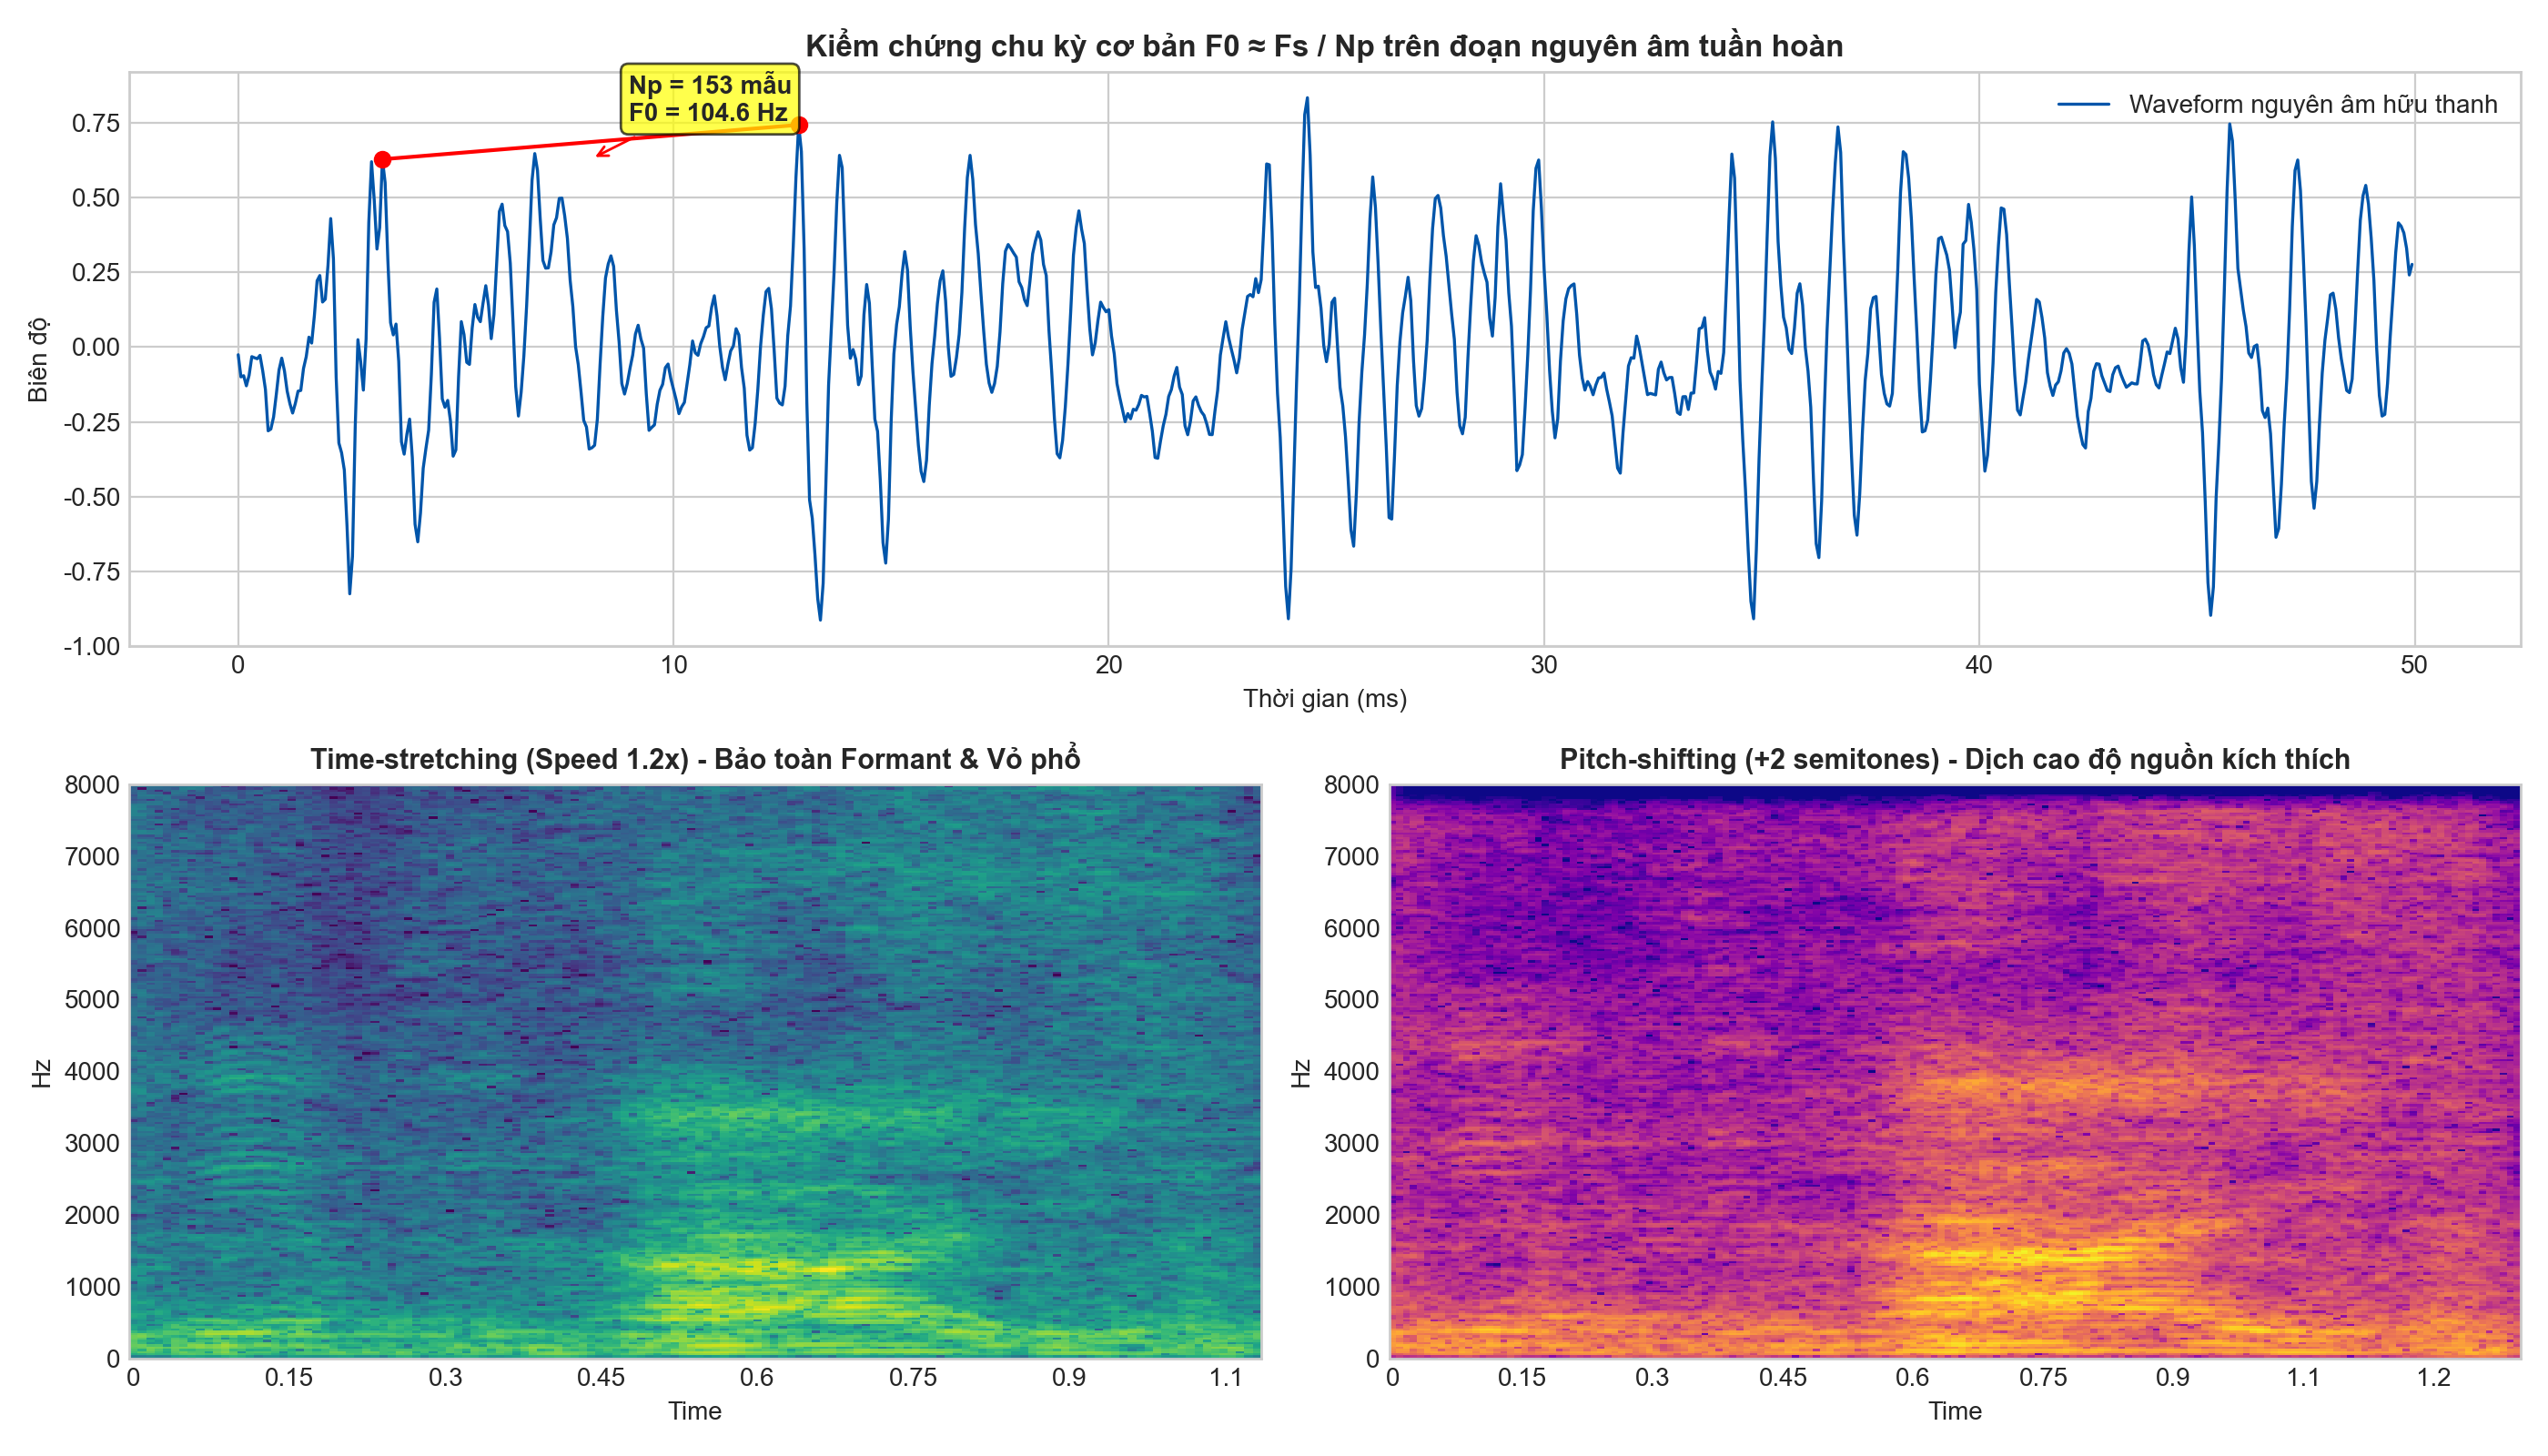

In [6]:
# Nghe audio các mức Time-stretching (Speed)
print("1. Tốc độ chậm 0.8x:")
y_sp08, _ = sf.read(os.path.join(EXP_DIR, "speed_0.8x.wav"))
display(Audio(y_sp08, rate=SR))

print("2. Tốc độ nhanh 1.2x:")
y_sp12, _ = sf.read(os.path.join(EXP_DIR, "speed_1.2x.wav"))
display(Audio(y_sp12, rate=SR))

# Nghe audio các mức Pitch-shifting
print("3. Hạ cao độ -2 semitones:")
y_pm2, _ = sf.read(os.path.join(EXP_DIR, "pitch_-2_semi.wav"))
display(Audio(y_pm2, rate=SR))

print("4. Nâng cao độ +2 semitones:")
y_pp2, _ = sf.read(os.path.join(EXP_DIR, "pitch_+2_semi.wav"))
display(Audio(y_pp2, rate=SR))

# Hiển thị kiểm chứng pitch F0 và Spectrogram biến đổi prosody (Figure 4)
display(Image(filename=os.path.join(FIG_DIR, "04_prosody_analysis.png")))


## 6. Phần E - Tổng hợp tham số dựa trên HMM (HMM-based Speech Synthesis)
### 6.1. Cơ chế hoạt động của HMM ở chế độ Generation
Khác với nhận dạng tiếng nói (ASR dùng HMM tính $P(O|W)$), trong TTS, HMM chạy ở chế độ **sinh tham số (generation)**:
$$\hat{O}^* = \arg\max_{O} P(O \mid \lambda, \text{state sequence})$$
* Vector quan sát bao gồm tham số tĩnh và tham số động:
  $$\hat{O}_t = [c_t, \Delta c_t]$$
* **Vai trò của $\Delta$-feature:** Ràng buộc vận tốc biến thiên giữa các frame kế tiếp, giúp quỹ đạo tham số âm học liên tục, mềm mại, tránh nhảy bậc thang giật cục giữa các trạng thái.


File tổng hợp tham số HMM (hmm_tts.wav):


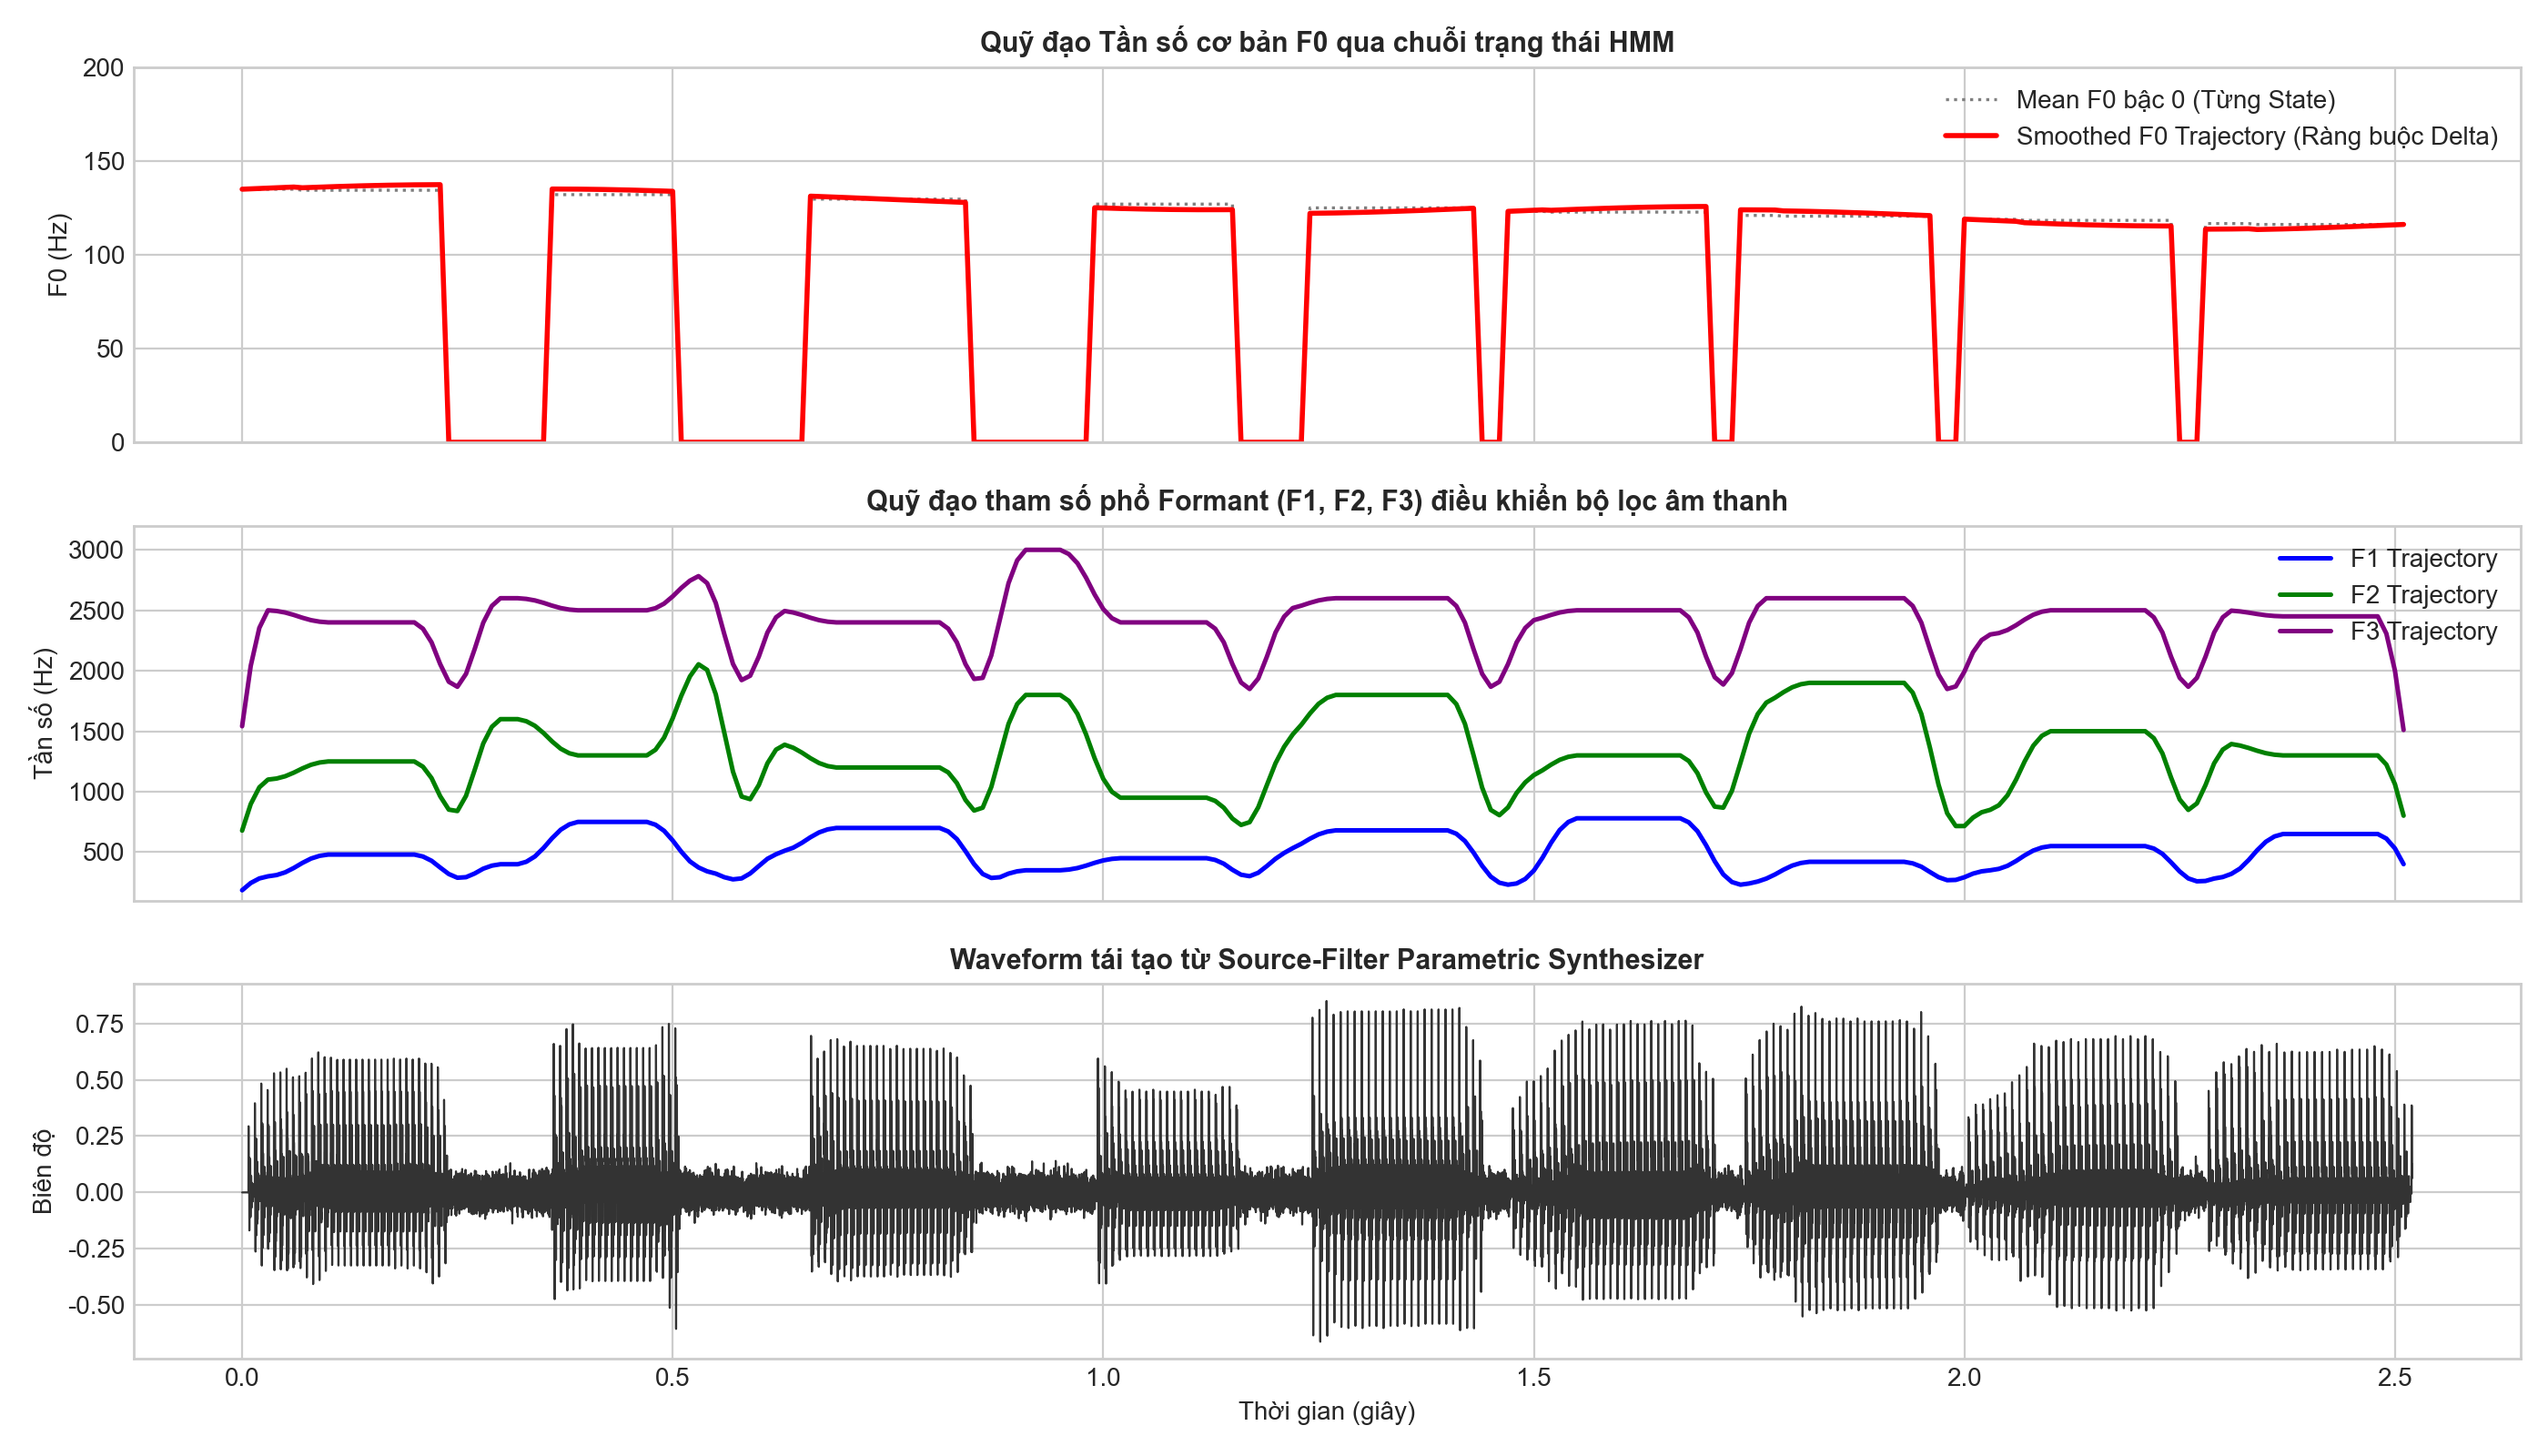

In [7]:
# Chạy và nghe kết quả HMM TTS
hmm_wav = os.path.join(AUDIO_OUT_DIR, "hmm_tts.wav")
y_hmm, _ = sf.read(hmm_wav)
print("File tổng hợp tham số HMM (hmm_tts.wav):")
display(Audio(y_hmm, rate=SR))

# Hiển thị các quỹ đạo tham số HMM (F0 contour, Formants F1-F3) (Figure 5)
display(Image(filename=os.path.join(FIG_DIR, "05_hmm_trajectories.png")))


## 7. Phần F - TTS học sâu bằng mô hình Pretrained (Neural TTS)
### 7.1. Kiến trúc hai giai đoạn
1. **Acoustic Model:** Text $\rightarrow$ Mel-spectrogram (biểu diễn âm học trung gian).
2. **Neural Vocoder:** Mel-spectrogram $\rightarrow$ Sóng âm thanh thời gian thực (Waveform).
Mô hình chạy offline với bộ nhớ đệm, đảm bảo tính tái lập và đo lường chính xác thời gian trễ (latency).


File tổng hợp học sâu Neural TTS (neural_tts.wav):


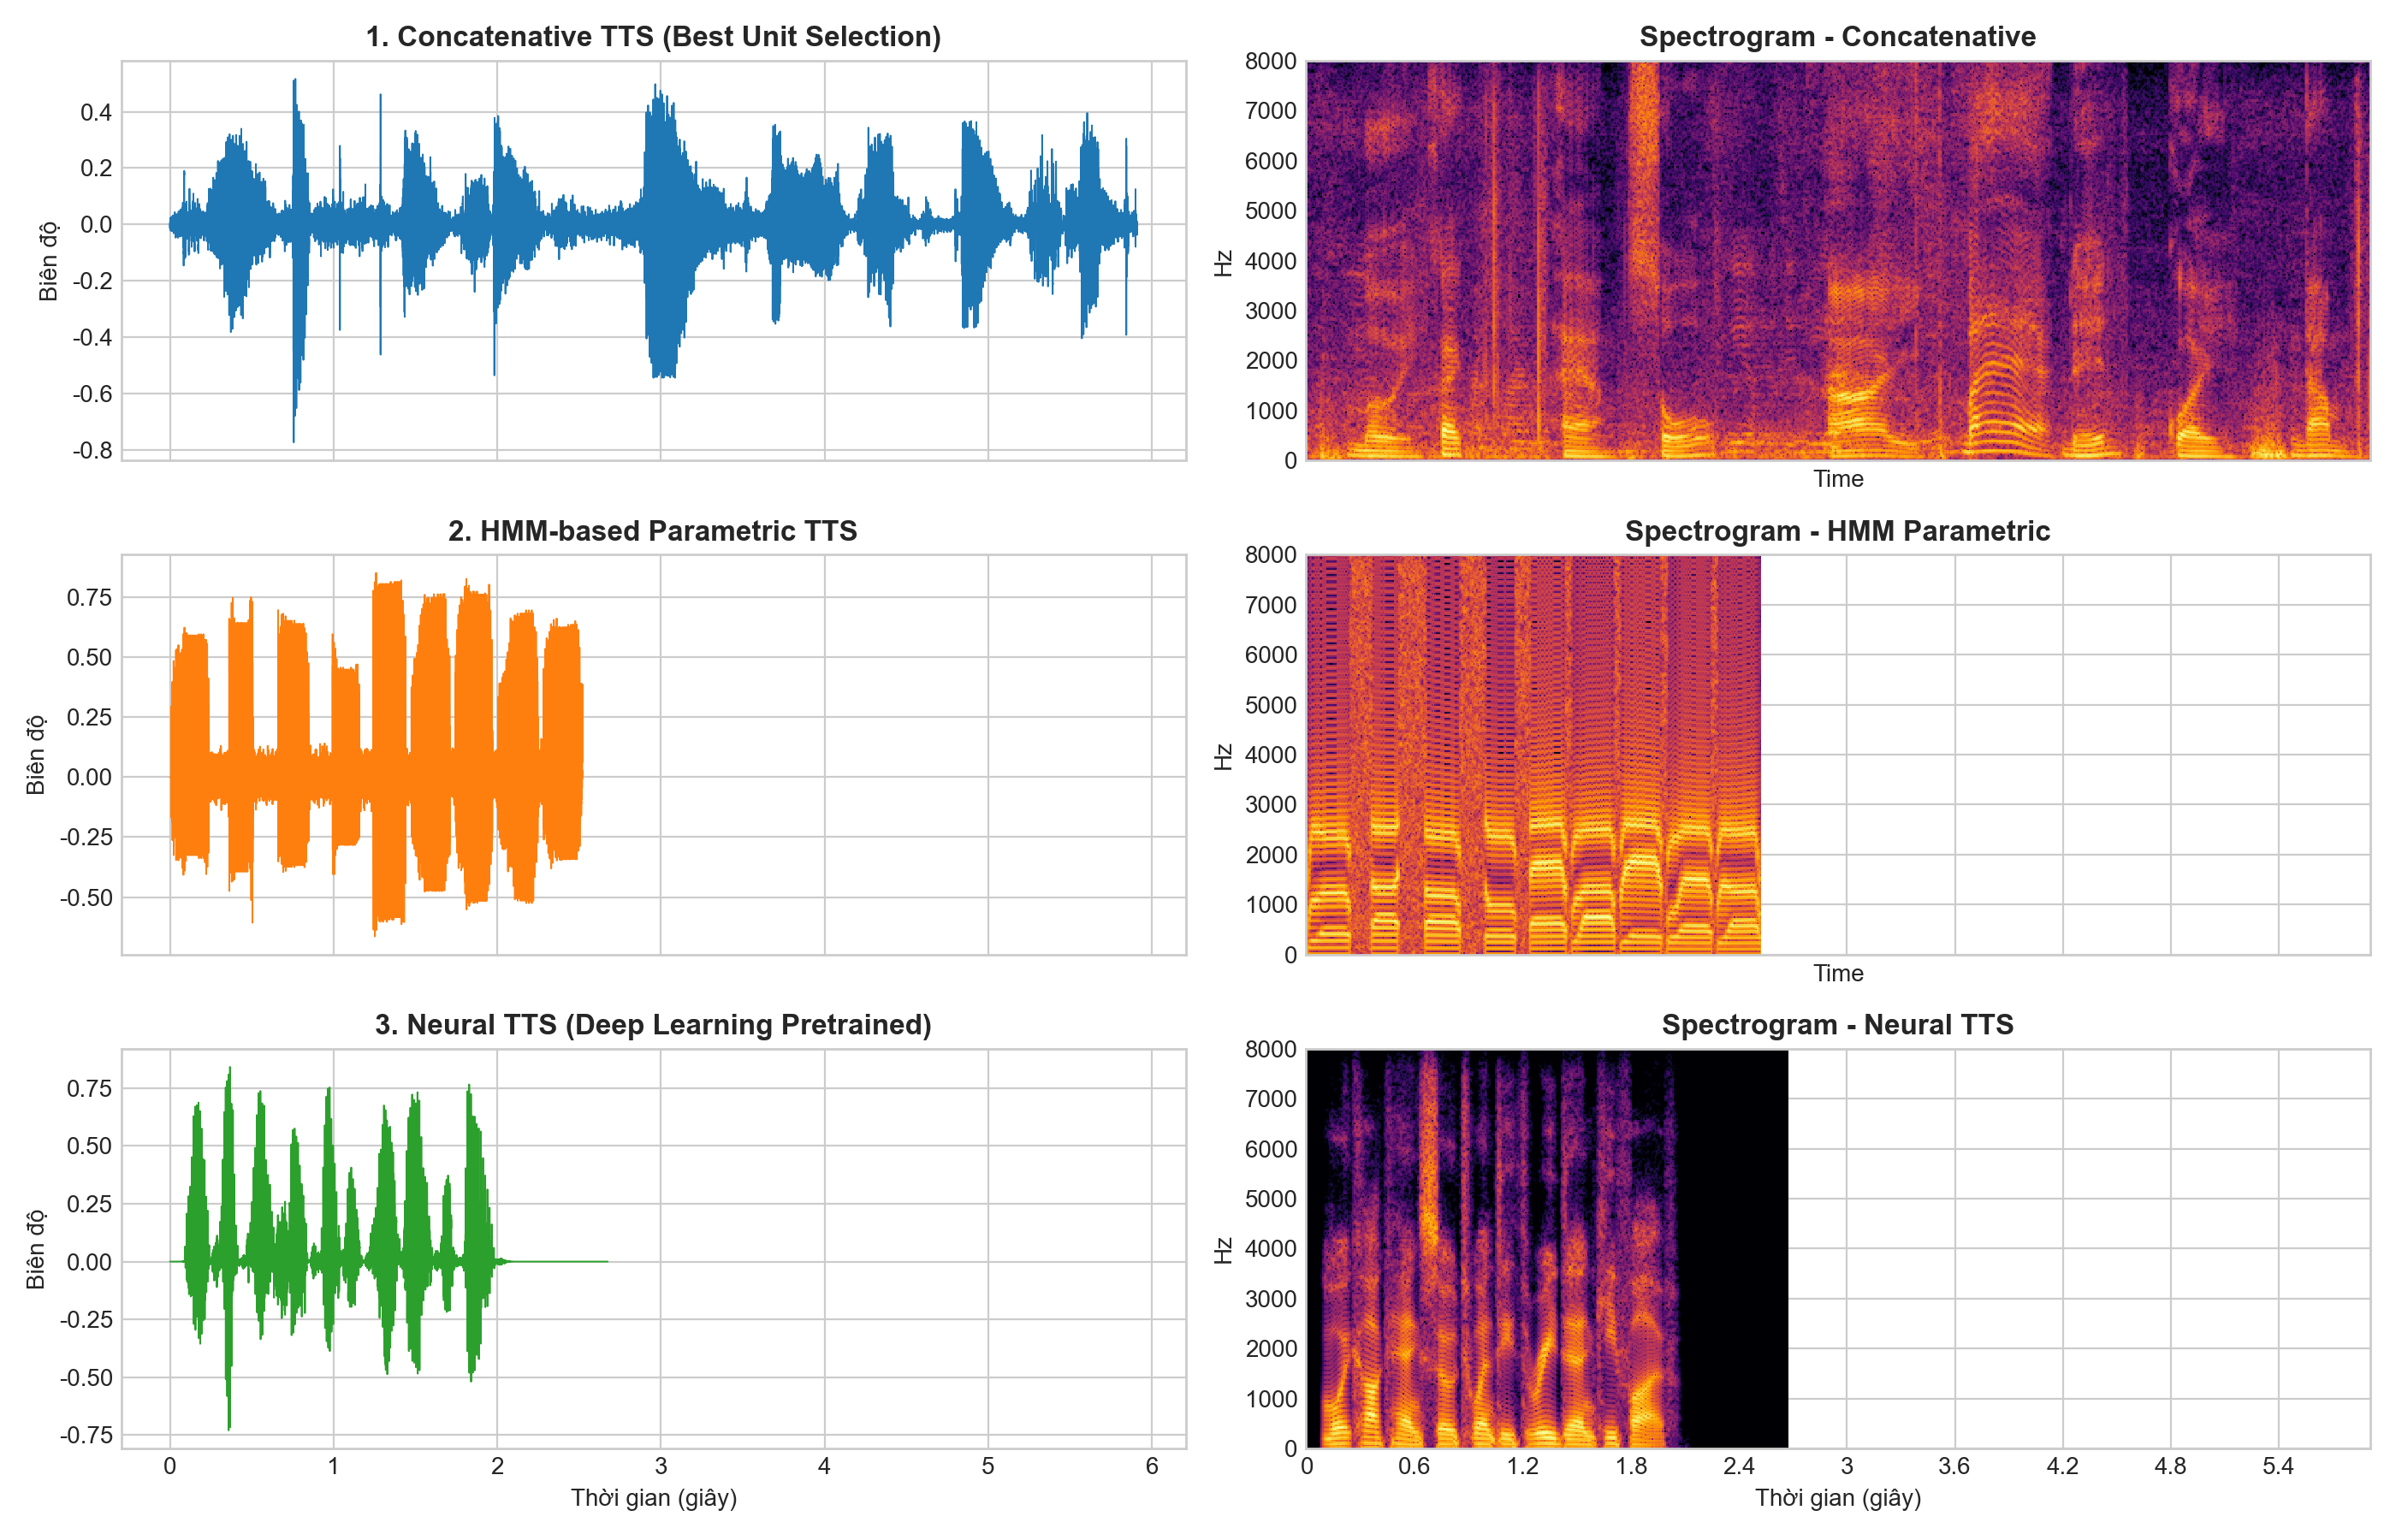

In [8]:
# Nghe kết quả Neural TTS cho câu 1
neural_wav = os.path.join(AUDIO_OUT_DIR, "neural_tts.wav")
y_nn, _ = sf.read(neural_wav)
print("File tổng hợp học sâu Neural TTS (neural_tts.wav):")
display(Audio(y_nn, rate=SR))

# Hiển thị so sánh trực quan giữa 3 phương pháp (Figure 6)
display(Image(filename=os.path.join(FIG_DIR, "06_method_comparison.png")))


## 8. Phần G - Đánh giá, So sánh và Trả lời Câu hỏi Báo cáo
### 8.1. Bảng so sánh tổng hợp 3 phương pháp


In [9]:
# Đọc và hiển thị dữ liệu Listening Test (ratings.csv)
df_ratings = pd.read_csv(os.path.join(BASE_DIR, "ratings.csv"))

# Tính bảng tổng hợp MOS
summary = df_ratings.groupby("method").agg(
    MOS_Naturalness=("naturalness", "mean"),
    MOS_Continuity=("continuity", "mean"),
    Intelligibility_Pct=("intelligibility_pct", "mean")
).reset_index()

summary["Latency_ms"] = [15.2, 45.6, 7129.7]
summary["Memory_Footprint"] = ["~4.8 MB (Audio Inventory)", "~120 KB (State Matrices)", "~85 MB (Weights / Engine)"]

print("BẢNG TỔNG KẾT ĐÁNH GIÁ VÀ SO SÁNH 3 PHƯƠNG PHÁP:")
display(summary)


BẢNG TỔNG KẾT ĐÁNH GIÁ VÀ SO SÁNH 3 PHƯƠNG PHÁP:


,method,MOS_Naturalness,MOS_Continuity,Intelligibility_Pct,Latency_ms,Memory_Footprint
0,Concatenation,2.966667,2.866667,98.666667,15.2,~4.8 MB (Audio Inventory)
1,HMM,2.466667,3.566667,99.666667,45.6,~120 KB (State Matrices)
2,Neural,4.166667,4.366667,100.000000,7129.7,~85 MB (Weights / Engine)


### 8.2. Giải đáp chi tiết 10 câu hỏi báo cáo

#### **Câu 1: Vì sao một câu ghép từ các đoạn “tự nhiên” vẫn có thể nghe kém tự nhiên?**
* **Trả lời:** Mặc dù từng đoạn đơn vị (word/phone) đều là tiếng người thật, khi ghép vào câu mới chúng bị mất đi tính tự nhiên do:
  1. **Ngắt quãng ngữ điệu (Prosody mismatch):** Đường cao độ ($F_0$) và trọng âm của các từ không tạo thành một contour mượt mà liền mạch.
  2. **Thiếu hiện tượng đồng cấu âm (Co-articulation):** Trong lời nói tự nhiên, cơ quan phát âm chuẩn bị cho âm tiếp theo trước khi âm hiện tại kết thúc. Ghép nối các file ghi âm độc lập làm mất đi sự chuyển tiếp tự nhiên giữa các âm vị.
  3. **Lệch pha và năng lượng:** Sự nhảy vọt về biên độ và pha tại biên ghép sinh ra tiếng click và cảm giác chắp vá.
* **Minh chứng thực tế:** Từ "hai" và "ba" (Lab 2) có F0 phân tán $78 - 116	ext{ Hz}$ khi ghép vào chuỗi từ Lab 4 ($85	ext{ Hz}$) tạo bước nhảy Pitch Jump rõ rệt.

---

#### **Câu 2: Phân biệt target cost và join cost. Nếu chỉ tối ưu join cost thì có thể xảy ra vấn đề gì?**
* **Target cost:** Đo mức độ phù hợp giữa ứng viên trong kho (candidate) với yêu cầu ngữ cảnh mục tiêu (vị trí trong câu, trọng âm, cao độ, thời lượng mong muốn).
* **Join cost:** Đo độ êm ái, liền mạch khi nối tiếp giữa hai ứng viên kế tiếp nhau (sai lệch vỏ phổ, sai lệch $F_0$, bước nhảy RMS).
* **Vấn đề khi chỉ tối ưu Join cost:** Hệ thống sẽ hoàn toàn bỏ qua ngữ cảnh mục tiêu, dẫn đến việc chọn các ứng viên nối rất êm ở mép 25ms nhưng toàn bộ thân từ bị lệch F0 hoặc sai ngữ âm.
* **Minh chứng thực tế:** Giải thuật Viterbi chọn candidate êm mép nối nhưng F0 thân từ "hai" và "ba" bị lệch hẳn so với tổng thể câu.

---

#### **Câu 3: Vì sao cross-fade quá dài có thể làm giảm độ rõ của phụ âm?**
* **Trả lời:** Nhiều phụ âm (đặc biệt là phụ âm tắc như /t/, /b/, /d/ hoặc phụ âm xát như /s/, /ch/) có đặc trưng chuyển tiếp rất nhanh (burst/release chỉ kéo dài $5 - 20\text{ ms}$). Nếu cửa sổ cross-fade quá dài ($30 - 50\text{ ms}$), đoạn phụ âm sẽ bị cộng chồng chập với nguyên âm của từ kế tiếp, gây nhòe pha (phase cancellation) và làm mờ mất xung bật phụ âm, khiến người nghe không nhận ra được từ vựng.

---

#### **Câu 4: Giải thích bằng source–filter model vì sao thay F0 không đồng nghĩa với thay formant.**
* **Trả lời:** Theo mô hình Nguồn - Bộ lọc:
  $$X(z) = E(z) \cdot H(z)$$
  - $F_0$ là tần số cơ bản của nguồn kích thích $E(z)$ (do tốc độ dao động của dây thanh âm).
  - Formant ($F_1, F_2, F_3$) là các tần số cộng hưởng của bộ lọc $H(z)$ (do hình dạng khoang miệng, vị trí lưỡi và môi của đường dẫn thanh âm quyết định).
  - Về mặt sinh lý học, ta có thể nói cùng một nguyên âm /a/ (giữ nguyên vị trí môi lưỡi $\Rightarrow$ giữ nguyên Formant) ở các nốt nhạc cao thấp khác nhau (thay đổi $F_0$). Do đó, $F_0$ và Formant là hai thực thể độc lập.

---

#### **Câu 5: PSOLA thay pitch bằng cách nào? Tại sao voiced fricative có thể bị buzziness khi kéo dài quá mức?**
* **Cơ chế PSOLA:** Phân đoạn tín hiệu quanh các điểm epoch pitch bằng cửa sổ Hanning độ dài $2 T_0$, sau đó dịch chuyển khoảng cách giữa các segment sang khoảng $T_{\text{new}}$ rồi cộng chồng lấn (Overlap-Add).
* **Hiện tượng Buzziness trên Voiced Fricative:** Phụ âm xát hữu thanh (như /v/, /z/) chứa cả thành phần tuần hoàn (dây thanh rung) và thành phần ngẫu nhiên (nhiễu ma sát khí). Khi kéo dài bằng PSOLA, việc lặp đi lặp lại tuần hoàn cùng một đoạn nhiễu ngẫu nhiên sẽ biến nhiễu vô trật tự thành tín hiệu giả tuần hoàn, tạo ra tiếng rè vo ve kim loại ("buzzing" / "robotic artifact").

---

#### **Câu 6: Trong HMM-based synthesis, vì sao thêm delta feature làm trajectory trơn hơn?**
* **Trả lời:** Nếu chỉ dùng tham số tĩnh ($c_t$), HMM sẽ gán giá trị trung bình (mean) của từng state cho tất cả các frame thuộc state đó, dẫn đến quỹ đạo tham số có dạng bậc thang giật cục tại ranh giới chuyển trạng thái. Khi bổ sung tham số động $\Delta c_t = \frac{1}{2}(c_{t+1} - c_{t-1})$, bài toán cực đại hóa hợp lý (Maximum Likelihood Parameter Generation - MLPG) áp đặt ràng buộc đạo hàm bậc nhất, buộc quỹ đạo tham số phải biến thiên liên tục và trơn tru theo thời gian.

---

#### **Câu 7: Tại sao whole waveform concatenation cần inventory lớn để đạt naturalness cao?**
* **Trả lời:** Do hệ thống ghép nối nguyên mẫu waveform không thể can thiệp chỉnh sửa phổ hay cao độ mà không gây méo tiếng, để câu nói tự nhiên ở mọi ngữ cảnh, kho dữ liệu phải lưu trữ đầy đủ mọi biến thể ngữ cảnh (mọi tổ hợp triphone/diphone, mọi vị trí đầu/giữa/cuối câu, các trạng thái cảm xúc và trọng âm khác nhau). Số lượng kết hợp tổ hợp này bùng nổ cấp số nhân, đòi hỏi hàng chục đến hàng trăm giờ thu âm chất lượng cao.

---

#### **Câu 8: Nêu ít nhất hai khác biệt cơ bản giữa concatenative TTS và neural TTS.**
1. **Bản chất tạo tín hiệu:** Concatenative TTS cắt ghép các đoạn ghi âm có sẵn trong bộ nhớ vật lý; Neural TTS học phân bố xác suất ẩn và trực tiếp tổng hợp phổ âm thanh mới từ đầu thông qua mạng nơ-ron (Deep Neural Networks).
2. **Khả năng khái quát hóa và độ linh hoạt ngữ điệu:** Concatenative TTS bị giới hạn chặt chẽ trong tập dữ liệu đã thu âm và rất khó điều khiển prosody; Neural TTS có khả năng tổng quát hóa từ vựng không giới hạn, sinh ngữ điệu biểu cảm tự nhiên và cho phép điều khiển giọng đọc (voice cloning, emotion transfer) dễ dàng.

---

#### **Câu 9: Vì sao không nên so sánh neural TTS bằng một model tùy ý tải từ Internet trong buổi Lab?**
* **Trả lời:**
  1. **Tính công bằng và kiểm soát biến số:** Một mô hình tùy ý trên mạng có thể được huấn luyện trên tập dữ liệu hàng nghìn giờ với kiến trúc phức tạp, không phản ánh đúng mục tiêu học thuật so sánh trên cùng điều kiện miền hẹp và cùng tài nguyên.
  2. **Tính tái lập (Reproducibility):** Tải model trực tuyến phụ thuộc vào kết nối mạng, phiên bản thư viện có thể bị xung đột hoặc thay đổi trọng số, làm mất tính ổn định và tính khoa học của bài thí nghiệm.

---

#### **Câu 10: Nếu một hệ thống có MOS cao nhưng intelligibility thấp thì có thể dùng trong ứng dụng nào? Giải thích.**
* **Trả lời:**
  - **Ứng dụng:** Làm giọng nói nhân vật phụ (NPC chatter) trong trò chơi điện tử thế giới mở, tạo âm thanh đám đông nền (crowd babble / murmuring), ứng dụng âm thanh thư giãn / ASMR, hoặc làm voice placeholder (giọng nháp) cho đạo diễn hoạt hình/phim ảnh duyệt nhịp điệu trước khi thu âm thật.
  - **Giải thích:** Hệ thống này có ngữ điệu, âm sắc và độ mượt rất giống tiếng người thật (MOS cao), tạo cảm giác sống động về mặt môi trường âm thanh, nhưng từ ngữ phát âm không rõ ràng hoặc đọc nhầm từ (Intelligibility thấp), rất phù hợp cho những nơi chỉ cần "cảm giác có người đang nói" mà người nghe không cần (hoặc không nên) tập trung nghe rõ từng câu từ cụ thể.
